# Predicting KCSE Performance For The Class Of 2026

## 1. Data Understanding

In [43]:
#Loading the necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
#Importing and loading the dataset
kcse_df=pd.read_csv(r"C:\Users\Hp\Downloads\kcse_dataset.csv")
kcse_df.head(10)

,Student_ID,Study_Hours,Attendance,Parental_Involvement,Drug_Use,Extra_Curricular,Mock_Score,Kcse_predicted_grade
0,STD0001,NaN,80.366810,High,No,NaN,29.656642,6.0
1,STD0002,2.834083,83.411768,High,No,Moderate,69.806833,6.0
2,STD0003,3.777226,NaN,med,No,Active,49.717405,3.0
3,STD0004,4.827636,90.807031,med,No,Active,58.637806,6.0
4,STD0005,2.719016,54.334959,High,No,Active,57.697681,5.0
5,STD0006,2.719036,60.932624,Medium,No,Active,49.977216,3.0
6,STD0007,4.895055,82.725529,Low,No,Moderate,84.625410,4.0
7,STD0008,3.920922,82.706789,Low,No,Moderate,54.291030,5.0
8,STD0009,2.436631,82.725715,High,No,NaN,31.630715,3.0
9,STD0010,3.651072,132.790972,Low,No,NaN,48.994280,6.0


From the overview of the dataframe we can deduce that some of the columns have null values and there is inconsistency on how texts are written ie.
Medium-med

In [4]:
#The size and shape of the dataframe
print(f'The shape of the dataframe is:', kcse_df.shape)
print(f'The size of the dataframe is:', kcse_df.size)

The shape of the dataframe is: (200, 8)
The size of the dataframe is: 1600


In [5]:
#Printing information about the dataframe
kcse_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            200 non-null    object 
 1   Study_Hours           190 non-null    float64
 2   Attendance            190 non-null    float64
 3   Parental_Involvement  200 non-null    object 
 4   Drug_Use              200 non-null    object 
 5   Extra_Curricular      143 non-null    object 
 6   Mock_Score            190 non-null    float64
 7   Kcse_predicted_grade  200 non-null    float64
dtypes: float64(4), object(4)
memory usage: 12.6+ KB


The summary shows many null values in columns such as the:
i.) Study_Hours
ii.) Attendance
iii.)Extra_Curricular
iv.) Mock_Score
It also shows that some data types are mixed up and incorrect and thus we should clean the data

## 2. Data Cleaning

### 2.1 Identify Problems in the Data

In [6]:
# Check missing values
print(kcse_df.isnull().sum())

# Check unique values (to spot inconsistencies)
print(kcse_df['Parental_Involvement'].unique())
print(kcse_df['Drug_Use'].unique())
print(kcse_df['Extra_Curricular'].unique())

# Check duplicates
print(kcse_df.duplicated().sum())

# Check Data types
kcse_df.dtypes

Student_ID               0
Study_Hours             10
Attendance              10
Parental_Involvement     0
Drug_Use                 0
Extra_Curricular        57
Mock_Score              10
Kcse_predicted_grade     0
dtype: int64
['High' 'med' 'Medium' 'Low']
['No' 'Yes' 'YES']
[nan 'Moderate' 'Active' 'active']
0


Student_ID               object
Study_Hours             float64
Attendance              float64
Parental_Involvement     object
Drug_Use                 object
Extra_Curricular         object
Mock_Score              float64
Kcse_predicted_grade    float64
dtype: object

### 2.2 Handling Missing Values(Null Values)

In [7]:
#Filling the numerical columns with the mean
kcse_df['Study_Hours'] = kcse_df['Study_Hours'].fillna(kcse_df['Study_Hours'].mean())
kcse_df['Attendance'] = kcse_df['Attendance'].fillna(kcse_df['Attendance'].mean())
kcse_df['Mock_Score'] = kcse_df['Mock_Score'].fillna(kcse_df['Mock_Score'].mean())

In [8]:
kcse_df.head(20)

,Student_ID,Study_Hours,Attendance,Parental_Involvement,Drug_Use,Extra_Curricular,Mock_Score,Kcse_predicted_grade
0,STD0001,3.168261,80.366810,High,No,NaN,29.656642,6.0
1,STD0002,2.834083,83.411768,High,No,Moderate,69.806833,6.0
2,STD0003,3.777226,77.794738,med,No,Active,49.717405,3.0
3,STD0004,4.827636,90.807031,med,No,Active,58.637806,6.0
4,STD0005,2.719016,54.334959,High,No,Active,57.697681,5.0
5,STD0006,2.719036,60.932624,Medium,No,Active,49.977216,3.0
6,STD0007,4.895055,82.725529,Low,No,Moderate,84.625410,4.0
7,STD0008,3.920922,82.706789,Low,No,Moderate,54.291030,5.0
8,STD0009,2.436631,82.725715,High,No,NaN,31.630715,3.0
9,STD0010,3.651072,132.790972,Low,No,NaN,48.994280,6.0


*The null values were filled using mean to preserve to maintain the size and distribtion of data
*Use of 'inplace=true' to prevent later reassignment
*No duplcates were found

In [9]:
#Filling thr categorical column
kcse_df['Extra_Curricular'] = kcse_df['Extra_Curricular'].fillna('none')

### 2.3 Fixing inconsistent categorical values

In [10]:
# Standardize lowercase first
kcse_df['Parental_Involvement'] = kcse_df['Parental_Involvement'].str.lower()
kcse_df['Drug_Use'] = kcse_df['Drug_Use'].str.lower()
kcse_df['Extra_Curricular'] = kcse_df['Extra_Curricular'].str.lower()

# Fix inconsistencies
kcse_df['Parental_Involvement'] = kcse_df['Parental_Involvement'].replace({'med': 'medium'})

In [11]:
kcse_df.head(10)

,Student_ID,Study_Hours,Attendance,Parental_Involvement,Drug_Use,Extra_Curricular,Mock_Score,Kcse_predicted_grade
0,STD0001,3.168261,80.366810,high,no,none,29.656642,6.0
1,STD0002,2.834083,83.411768,high,no,moderate,69.806833,6.0
2,STD0003,3.777226,77.794738,medium,no,active,49.717405,3.0
3,STD0004,4.827636,90.807031,medium,no,active,58.637806,6.0
4,STD0005,2.719016,54.334959,high,no,active,57.697681,5.0
5,STD0006,2.719036,60.932624,medium,no,active,49.977216,3.0
6,STD0007,4.895055,82.725529,low,no,moderate,84.625410,4.0
7,STD0008,3.920922,82.706789,low,no,moderate,54.291030,5.0
8,STD0009,2.436631,82.725715,high,no,none,31.630715,3.0
9,STD0010,3.651072,132.790972,low,no,none,48.994280,6.0


### 2.4 Fixing Data Types

In [12]:
# Convert Categorical Columns
kcse_df['Parental_Involvement'] = kcse_df['Parental_Involvement'].astype('category')
kcse_df['Drug_Use'] = kcse_df['Drug_Use'].astype('category')
kcse_df['Extra_Curricular'] = kcse_df['Extra_Curricular'].astype('category')
# Convert Target Variable
kcse_df['Kcse_predicted_grade'] = kcse_df['Kcse_predicted_grade'].astype(int)
kcse_df.dtypes

Student_ID                object
Study_Hours              float64
Attendance               float64
Parental_Involvement    category
Drug_Use                category
Extra_Curricular        category
Mock_Score               float64
Kcse_predicted_grade       int64
dtype: object

Categorical variables were converted to appropriate formats to enable analysis and modeling, while numerical variables were retained for statistical computations.

### 2.5 Handle outliers

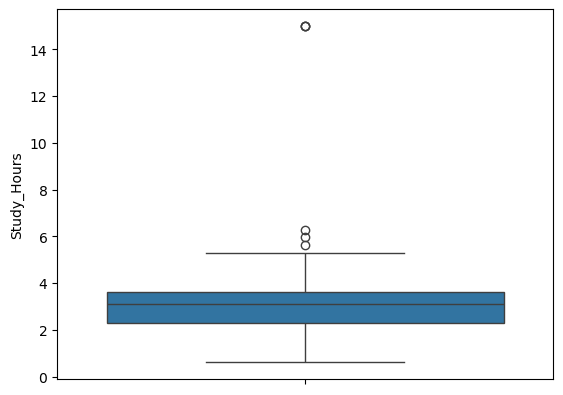

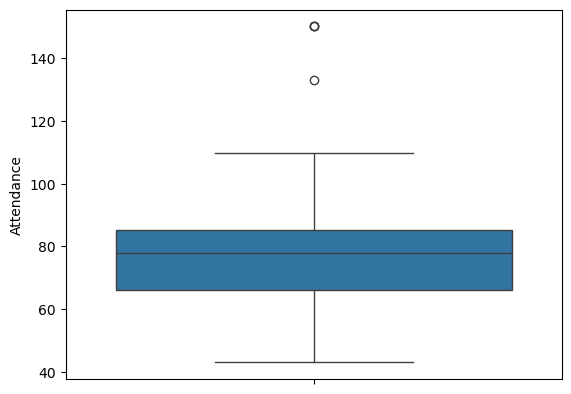

In [13]:
# Detect Outliers
sns.boxplot(kcse_df['Study_Hours'])
plt.show()

sns.boxplot(kcse_df['Attendance'])
plt.show()

There are a few outliers. 
Outlier- Anomaly in the dataset

In [14]:
# Fix Outlier using capping method
# Cap study hours (max 10 hours)
kcse_df['Study_Hours'] = kcse_df['Study_Hours'].clip(0, 10)

# Cap attendance (max 100%)
kcse_df['Attendance'] = kcse_df['Attendance'].clip(0, 100)

### 2.6 Verification of cleaning

In [15]:
print(kcse_df.isnull().sum())
print(kcse_df.describe())
print(kcse_df.head())

Student_ID              0
Study_Hours             0
Attendance              0
Parental_Involvement    0
Drug_Use                0
Extra_Curricular        0
Mock_Score              0
Kcse_predicted_grade    0
dtype: int64
       Study_Hours  Attendance  Mock_Score  Kcse_predicted_grade
count   200.000000  200.000000  200.000000            200.000000
mean      3.093261   76.584114   54.317658              4.700000
std       1.369266   13.302897   14.046149              1.878201
min       0.614917   43.141564    2.787868              1.000000
25%       2.309820   66.151254   45.191307              3.000000
50%       3.118037   77.772434   54.963525              5.000000
75%       3.618523   85.308467   64.333478              6.000000
max      10.000000  100.000000   90.360645             10.000000
  Student_ID  Study_Hours  Attendance Parental_Involvement Drug_Use  \
0    STD0001     3.168261   80.366810                 high       no   
1    STD0002     2.834083   83.411768               

## 3. Exploratory Data Analysis

### 3.1 Single variable Analysis 

#### 3.1.1 Numerical Variables

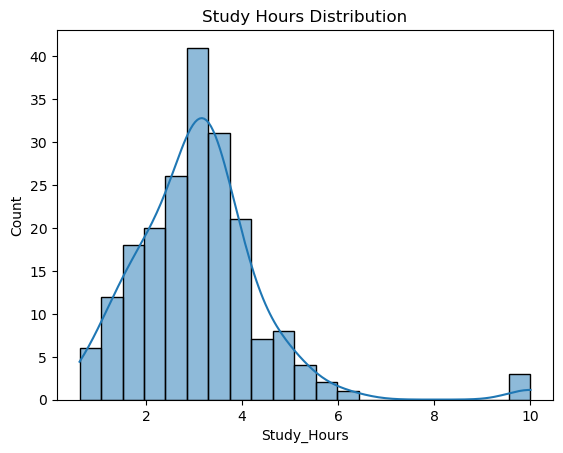

In [16]:
# Study hours
kcse_df['Study_Hours'].describe()
sns.histplot(kcse_df['Study_Hours'], kde=True)
plt.title("Study Hours Distribution")
plt.show()

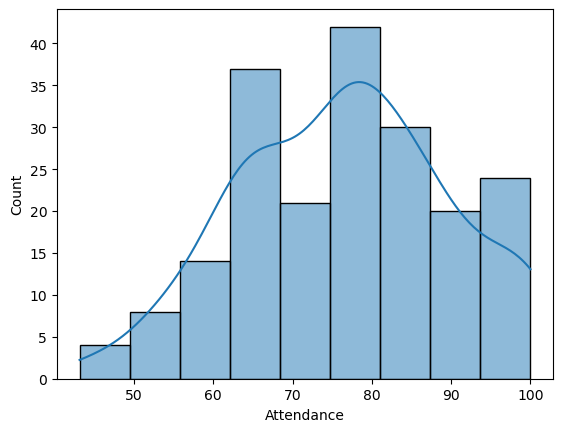

In [17]:
# Attendance
kcse_df['Attendance'].describe()
sns.histplot(kcse_df['Attendance'], kde=True)
plt.show()

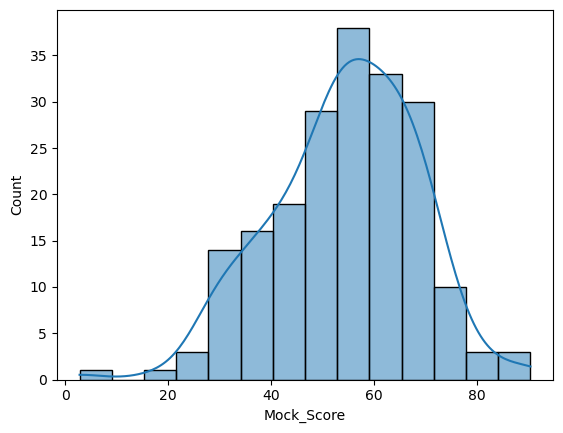

In [18]:
# Mock score
kcse_df['Mock_Score'].describe()
sns.histplot(kcse_df['Mock_Score'], kde=True)
plt.show()

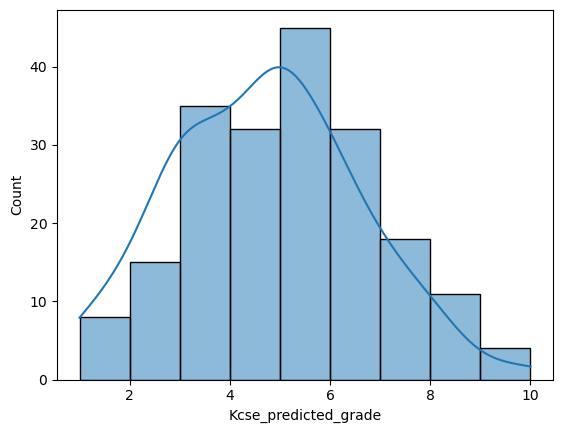

In [19]:
# KCSE Predicted Grade
kcse_df['Kcse_predicted_grade'].describe()
sns.histplot(kcse_df['Kcse_predicted_grade'], kde=True)
plt.show()

#### 3.1.2 Categorical Variables

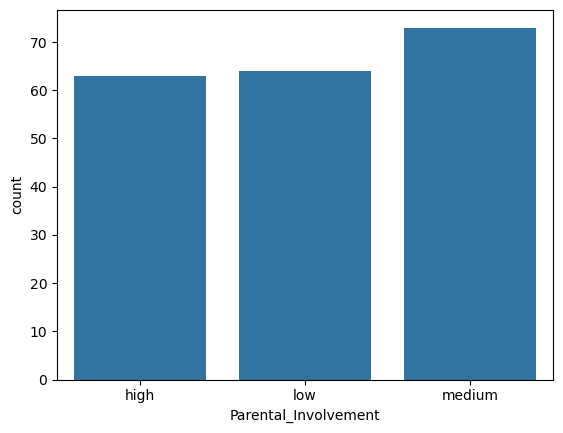

In [20]:
# Parental Involvement 
kcse_df['Parental_Involvement'].value_counts()
sns.countplot(x='Parental_Involvement', data=kcse_df)
plt.show()

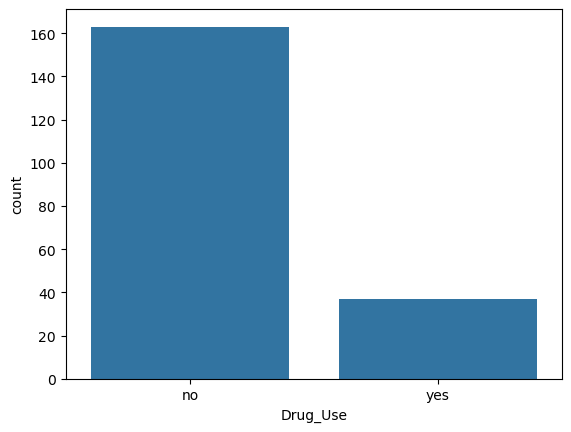

In [21]:
# Drug Usage
kcse_df['Drug_Use'].value_counts()
sns.countplot(x='Drug_Use', data=kcse_df)
plt.show()

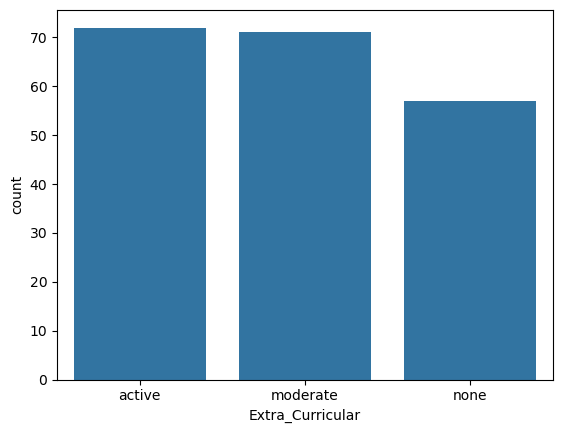

In [22]:
# Extra Curricular
kcse_df['Extra_Curricular'].value_counts()
sns.countplot(x='Extra_Curricular', data=kcse_df)
plt.show()

### 3.2 Two Variable Analysis

#### 3.2.1 Study Hours vs KCSE Predicted Grade

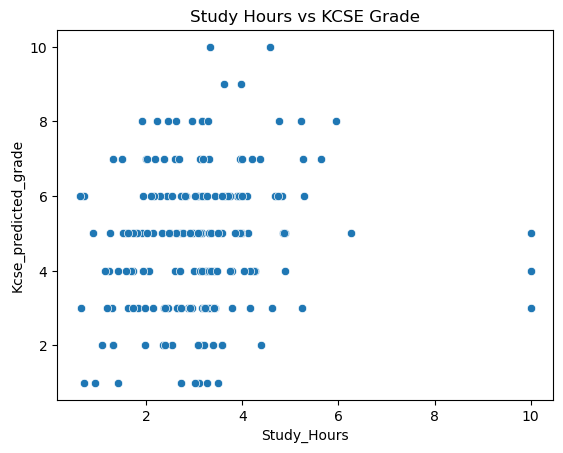

In [23]:
sns.scatterplot(x='Study_Hours', y='Kcse_predicted_grade', data=kcse_df)
plt.title("Study Hours vs KCSE Grade")
plt.show()

#### 3.2.2 Attendance vs KCSE Predicted Grade

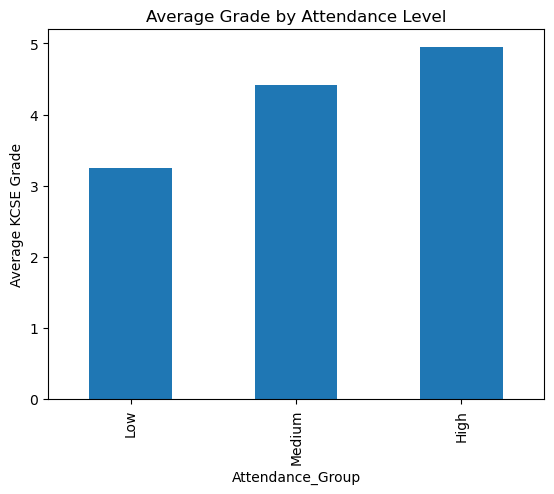

In [25]:
# Create attendance groups
kcse_df['Attendance_Group'] = pd.cut(kcse_df['Attendance'], bins=[0,50,75,100],
                                     labels=['Low','Medium','High'])

# Plot average KCSE grade by attendance group
kcse_df.groupby('Attendance_Group', observed=True)['Kcse_predicted_grade'].mean().plot(kind='bar')

plt.title("Average Grade by Attendance Level")
plt.ylabel("Average KCSE Grade")
plt.show()


#### 3.2.3 Mock Score vs KCSE Predicted Grade

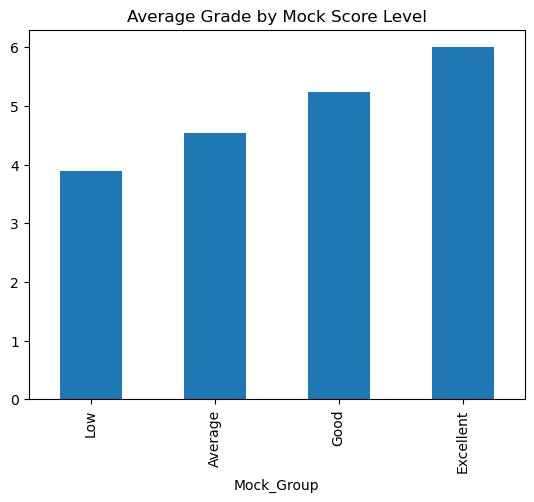

In [28]:
kcse_df['Mock_Group'] = pd.cut(kcse_df['Mock_Score'], bins=[0,40,60,80,100],
                              labels=['Low','Average','Good','Excellent'])

kcse_df.groupby('Mock_Group', observed=True)['Kcse_predicted_grade'].mean().plot(kind='bar')

plt.title("Average Grade by Mock Score Level")
plt.show()


#### 3.2.4 Drug Use vs KCSE Predicted Grade

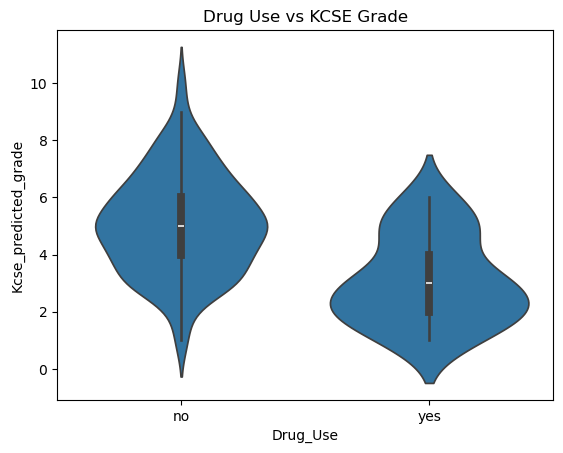

In [29]:
sns.violinplot(x='Drug_Use', y='Kcse_predicted_grade', data=kcse_df)
plt.title("Drug Use vs KCSE Grade")
plt.show()

#### 3.2.5 Parental Involvement vs KCSE Predicted Grade

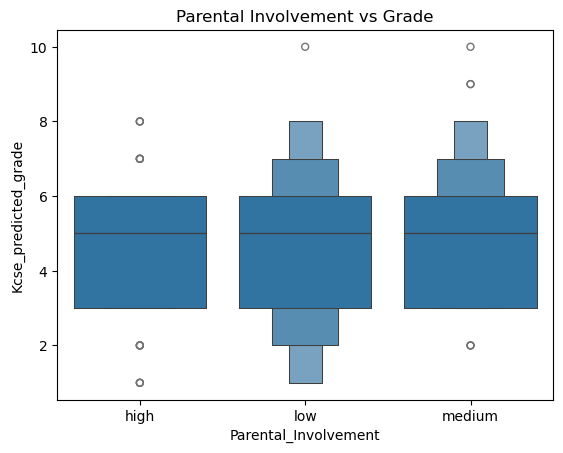

In [33]:
sns.boxenplot(x='Parental_Involvement', y='Kcse_predicted_grade', data=kcse_df)
plt.title("Parental Involvement vs Grade")
plt.show()

#### 3.2.5 Extra Curricular vs KCSE Predicted Grade

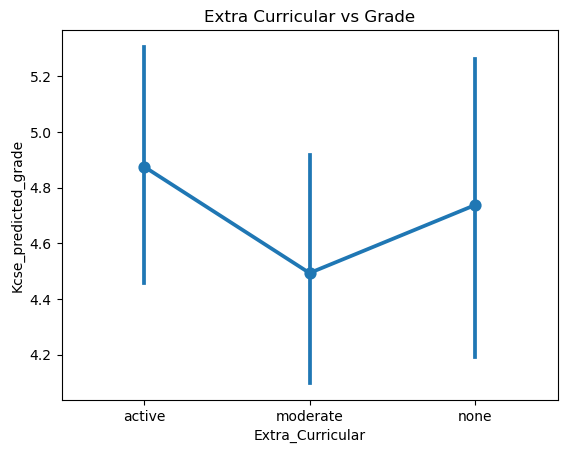

In [34]:
sns.pointplot(x='Extra_Curricular', y='Kcse_predicted_grade', data=kcse_df)
plt.title("Extra Curricular vs Grade")
plt.show()

### 3.3 Multi-variate Analysis

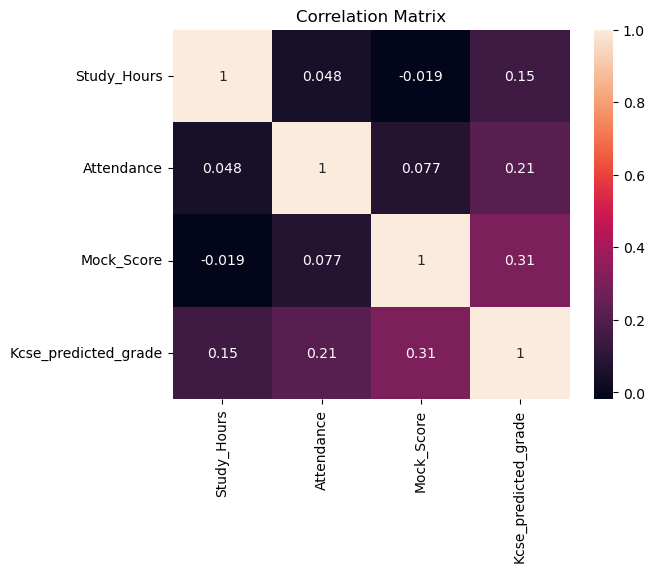

In [35]:
corr = kcse_df.corr(numeric_only=True)

sns.heatmap(corr, annot=True)
plt.title("Correlation Matrix")
plt.show()

## 4. Descriptive Statistics

### 4.1 Central Tendency and Overview

In [37]:
kcse_df.describe()

,Study_Hours,Attendance,Mock_Score,Kcse_predicted_grade
count,200.000000,200.000000,200.000000,200.000000
mean,3.093261,76.584114,54.317658,4.700000
std,1.369266,13.302897,14.046149,1.878201
min,0.614917,43.141564,2.787868,1.000000
25%,2.309820,66.151254,45.191307,3.000000
50%,3.118037,77.772434,54.963525,5.000000
75%,3.618523,85.308467,64.333478,6.000000
max,10.000000,100.000000,90.360645,10.000000


Most students are average performers.
Performance varies significantly across students.
Most students are clustered in the middle performance range.


### 4.2 Distribution

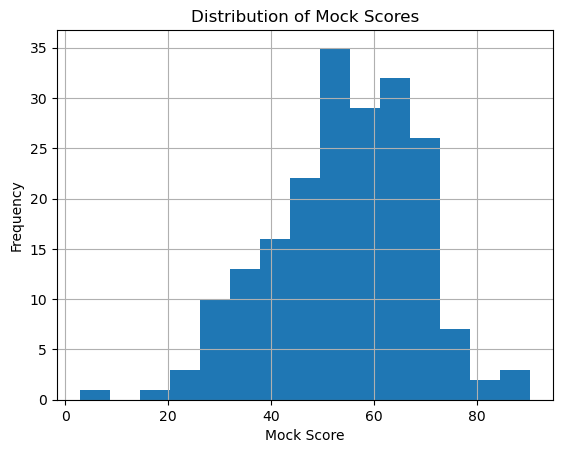

In [39]:
# Mock scores 
kcse_df['Mock_Score'].hist(bins=15)
plt.title("Distribution of Mock Scores")
plt.xlabel("Mock Score")
plt.ylabel("Frequency")
plt.show()

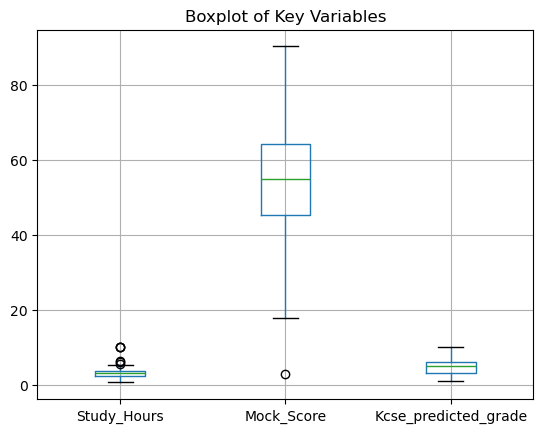

In [40]:
# Spread and outliers
kcse_df.boxplot(column=['Study_Hours', 'Mock_Score', 'Kcse_predicted_grade'])
plt.title("Boxplot of Key Variables")
plt.show()

Outliers were removed

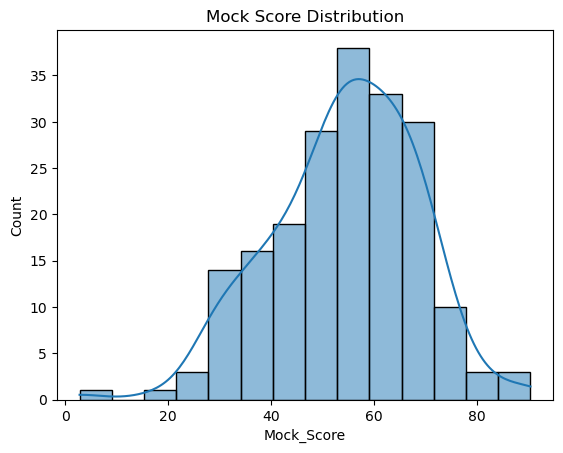

In [42]:
sns.histplot(kcse_df['Mock_Score'], kde=True)
plt.title("Mock Score Distribution")
plt.show()

### 4.3 Hypothesis Testing

#### 4.3.1 Hypothesis 1

##### Study Hours and KCSE Performance
*Null Hypothesis (H₀):
There is no statistically significant relationship between the number of study hours and KCSE predicted grades.
*Alternative Hypothesis (H₁):
There is a statistically significant relationship between study hours and KCSE predicted grades.

In [44]:
corr, p_value = stats.pearsonr(
    kcse_df['Study_Hours'].dropna(),
    kcse_df['Kcse_predicted_grade'].dropna()
)

print("Correlation:", corr)
print("P-value:", p_value)

Correlation: 0.15079723294792324
P-value: 0.033053629236720436


In [45]:
if p_value < 0.05:
    print("Reject H0 (Significant relationship)")
else:
    print("Fail to reject H0 (No significant relationship)")

Reject H0 (Significant relationship)


#### 4.3.2 Hypothesis 2

##### Attendance vs KCSE Grade
*H₀: Attendance has no significant effect on KCSE grades
*H₁: Attendance has a significant effect on KCSE grades

In [46]:
corr, p_value = stats.pearsonr(
    kcse_df['Attendance'].dropna(),
    kcse_df['Kcse_predicted_grade'].dropna()
)

print(corr, p_value)

0.21374496002348453 0.00237314879613631


In [47]:
if p_value < 0.05:
    print("Reject H0 (Significant relationship)")
else:
    print("Fail to reject H0 (No significant relationship)")

Reject H0 (Significant relationship)


#### 4.3.3 Hypothesis 3

##### Drug Use
*H₀: There is no significant difference in KCSE grades between students who use drugs and those who do not
*H₁: There is a significant difference in KCSE grades between the two groups

In [48]:
users = kcse_df[kcse_df['Drug_Use'] == 'yes']['Kcse_predicted_grade']
non_users = kcse_df[kcse_df['Drug_Use'] == 'no']['Kcse_predicted_grade']

t_stat, p_value = stats.ttest_ind(users, non_users, nan_policy='omit')

print("T-stat:", t_stat)
print("P-value:", p_value)

T-stat: -6.356822732974687
P-value: 1.3908993934164003e-09


In [49]:
if p_value < 0.05:
    print("Reject H0 (Significant relationship)")
else:
    print("Fail to reject H0 (No significant relationship)")

Reject H0 (Significant relationship)


#### 4.3.4 Hypothesis 4

##### Parental Involvement
H₀: All groups have the same mean KCSE grade
H₁: At least one group mean is different

In [50]:
low = kcse_df[kcse_df['Parental_Involvement'] == 'low']['Kcse_predicted_grade']
med = kcse_df[kcse_df['Parental_Involvement'] == 'medium']['Kcse_predicted_grade']
high = kcse_df[kcse_df['Parental_Involvement'] == 'high']['Kcse_predicted_grade']

f_stat, p_value = stats.f_oneway(low, med, high)

print("F-stat:", f_stat)
print("P-value:", p_value)

F-stat: 0.6050672579648705
P-value: 0.5470492600983574


In [51]:
if p_value < 0.05:
    print("Reject H0 (Significant relationship)")
else:
    print("Fail to reject H0 (No significant relationship)")

Fail to reject H0 (No significant relationship)


#### 4.3.5 Hypothesis 5

##### Extra Curricular
H₀: There is no significant difference in KCSE grades between participants and non-participants
H₁: There is a significant difference in KCSE grades

In [54]:
yes = kcse_df[kcse_df['Extra_Curricular'] == 'yes']['Kcse_predicted_grade']
no = kcse_df[kcse_df['Extra_Curricular'] == 'no']['Kcse_predicted_grade']

t_stat, p_value = stats.ttest_ind(yes, no, nan_policy='omit')

print(t_stat, p_value)

nan nan


In [55]:
kcse_df['Extra_Curricular'] = kcse_df['Extra_Curricular'].str.lower().str.strip()

In [56]:
print(kcse_df['Extra_Curricular'].value_counts())

Extra_Curricular
active      72
moderate    71
none        57
Name: count, dtype: int64


In [57]:
yes = kcse_df[kcse_df['Extra_Curricular'] == 'yes']['Kcse_predicted_grade']
no = kcse_df[kcse_df['Extra_Curricular'] == 'no']['Kcse_predicted_grade']

print(yes.count(), no.count())

0 0


In [58]:
if yes.count() > 10 and no.count() > 10:
    t_stat, p_value = stats.ttest_ind(yes, no, nan_policy='omit')
    print("T-stat:", t_stat)
    print("P-value:", p_value)
else:
    print("Sample size too small for t-test")

Sample size too small for t-test


In [ ]:
kcse_df.to_csv('kcse_cleaned.csv', index=False)